# 4. Variational Autoencoder (VAE)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.utils import save_image, make_grid
from pytorch_fid import fid_score

import hashlib
import matplotlib.pyplot as plt
import numpy as np
import os
import tqdm
import time
import seaborn as sns

# Check for GPU and set device
if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    device = torch.device("cuda")
    print(f"Using GPU: {device_name}")
else:
    device = torch.device("cpu")
    print("No GPU detected. Using CPU.")

# Fix seed for reproducible randomization.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print(f"Seed generated: {seed}")
rng = np.random.default_rng(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    
def add_username_to_plot(ax, userid=username):
    """Add the username watermark to a matplotlib plot."""
    # Using the exact code from the assignment PDF
    ax.text(
        0.95, -0.1,
        userid,
        ha='right', va='bottom',
        transform=ax.transAxes,
        fontsize=10, color='gray', alpha=0.7
    )
    
sns.set_theme(context="paper", style="darkgrid",
              palette="magma", font="Nimbus Roman")

Using GPU: NVIDIA GeForce GTX 1650


## 4.1 Introduction

Imported the Fashion-MNIST dataset through torch.

## 4.2 Dataset Preparation

Loaded Fashion-MNIST: 60000 train images, 10000 test images.


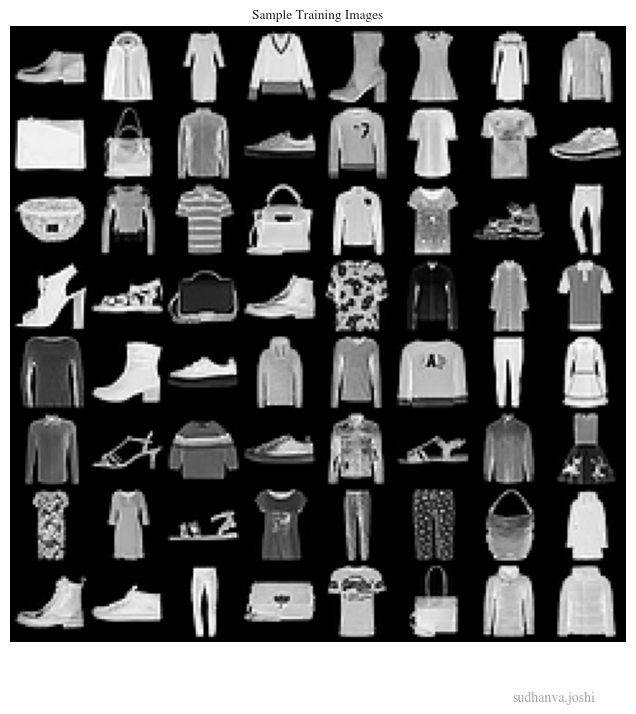

In [2]:
# Define batch size
BATCH_SIZE = 128

# Define transformation: ToTensor() scales images to [0, 1]
# This is ideal for the Binary Cross-Entropy (BCE) loss
transform = transforms.Compose([
    transforms.ToTensor()
])

# Load Fashion-MNIST dataset
train_dataset = datasets.FashionMNIST(
    root='./data/Q4/',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root='./data/Q4/',
    train=False,
    download=True,
    transform=transform
)

# Create DataLoader instances 
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"Loaded Fashion-MNIST: {len(train_dataset)} train images, {len(test_dataset)} test images.")

# Visualize a batch (optional check)
data_iter = iter(train_loader)
images, labels = next(data_iter)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(make_grid(images[:64], nrow=8).permute(1, 2, 0))
ax.set_title("Sample Training Images")
ax.axis('off')
add_username_to_plot(ax)
plt.show()

## 4.3 Model Architecture

In [3]:
class VAE(nn.Module):
    
    def __init__(self, z_dim=2):
        super(VAE, self).__init__()

        # Encoder
        self.encoder_net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),  # (32, 14, 14)
            nn.ELU(),
            nn.BatchNorm2d(32),
            
            nn.Conv2d(32, 64, 4, 2, 1), # (64, 7, 7)
            nn.ELU(),
            nn.BatchNorm2d(64),
            
            nn.Conv2d(64, 128, 4, 2, 1), # (128, 3, 3)
            nn.ELU(),
            nn.BatchNorm2d(128),
        )
        
        self.fc_mu = nn.Linear(128 * 3 * 3, z_dim)
        self.fc_logvar = nn.Linear(128 * 3 * 3, z_dim)
        self.decoder_fc = nn.Linear(z_dim, 128 * 3 * 3)
        
        self.decoder_net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1, output_padding=1),  # (64, 7, 7)
            nn.ReLU(),
            
            nn.ConvTranspose2d(64, 32, 4, 2, 1),   # (32, 14, 14)
            nn.ReLU(),
            
            nn.ConvTranspose2d(32, 1, 4, 2, 1),    # (1, 28, 28)
            nn.Sigmoid()
        )

    def encode(self, x):
        """Encoder forward pass"""
        # x shape is [B, 1, 28, 28]
        h = self.encoder_net(x)
        # h shape is [B, 128, 3, 3]
        h = h.view(-1, 128 * 3 * 3) 
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        """Reparameterization Trick"""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        """Decoder forward pass"""
        # z shape is [B, z_dim]
        h = self.decoder_fc(z)
        h = h.view(-1, 128, 3, 3)
        
        return self.decoder_net(h) # Output shape is [B, 1, 28, 28]

    def forward(self, x):
        """Full VAE forward pass"""
        # x shape is [B, 1, 28, 28]
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)
        return recon_x, mu, logvar
    
# Model Initialization 
# We use z_dim=2 (latent dimension) to allow for 2D visualization
# in section 4.6, as requested.
LATENT_DIM = 2
INPUT_DIM = 784 # 28*28
HIDDEN_DIM = 400

## 4.4 Loss Function

Reconstruction loss and KL divergence are the two main parts of a Variational Autoencoder (VAE) loss function.

**Reconstruction Loss**

* Ensures the output image looks like the input image.
* Measures how well the autoencoder can rebuild the input.
* Model learns to keep enough information in the latent variable *z* to reconstruct *x*.
* Binary Cross-Entropy loss:
  
  $$ L_{\text{recon}} = -[x \cdot \log(\hat{x}) + (1 - x) \cdot \log(1 - \hat{x})] $$
  
  where $\hat{x}$ is the reconstructed image.

**Kullback-Leibler Divergence**

* Makes the learned latent space smooth and continuous.
* Ensures that the encoded distribution $q(z|x)$ stays close to a normal distribution $N(0, 1)$.
* Acts as a regularization expression and prevents the model from memorizing the data. Allows random sampling of *z* to produce valid new images.
* KL Divergence loss:
  $$
  L_{\text{KL}} = -\frac{1}{2} \sum (1 + \log(\sigma^2) - \mu^2 - \sigma^2)
  $$
  where $\mu$ and $\sigma$ are the mean and standard deviation of $q(z|x)$.

**Total Loss**
$$
L_{\text{total}} = L_{\text{recon}} + L_{\text{KL}}
$$

In [ ]:
def vae_loss_function(recon_x, x, mu, logvar, beta=1.0):
    """
    Calculates the VAE loss = Reconstruction Loss + KL Divergence.
    L = Recon_Loss + beta * KL_Loss
    """
    # 1. Reconstruction Loss (BCE)
    # We use 'sum' reduction, as is common practice for VAEs,
    # to measure total loss over all pixels and batch items.
    BCE = F.binary_cross_entropy(recon_x, x, reduction='sum')
    
    # 2. KL Divergence, D_KL(q(z|x) || p(z)), p(z) is N(0, I)
    # Formula: -0.5 * sum(1 + log(sigma^2) - mu^2 - sigma^2)
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    
    total_loss = BCE + beta * KLD
    
    return total_loss, BCE, KLD

## 4.5 Training Procedure

Starting training for VAE (Beta=1.0).


Total Progress:   0%|          | 0/25 [06:35<?, ?it/s, KLD=6.2765, Test_Loss=261.6732, Train_Loss=259.3606]

Training complete.


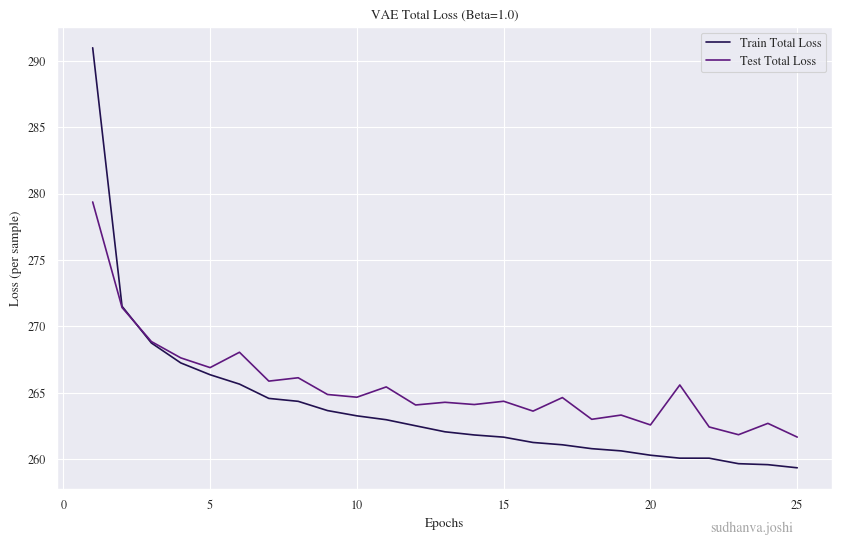

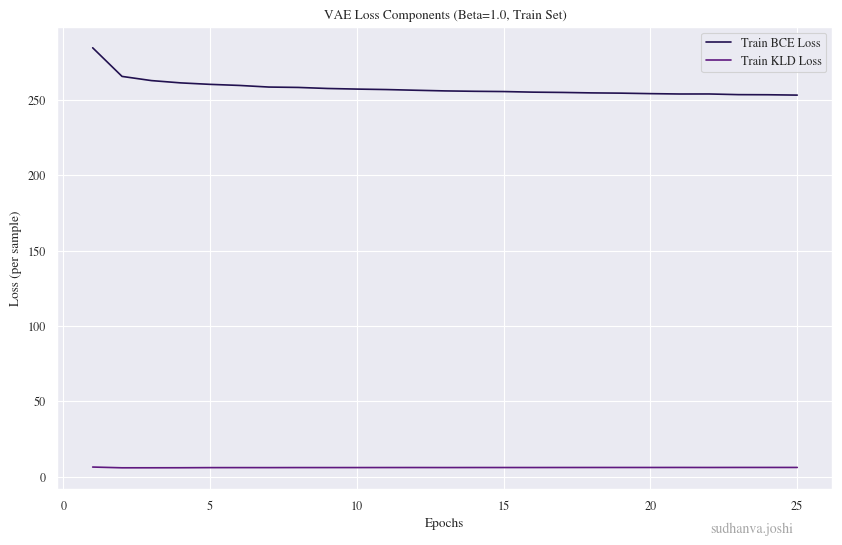

In [5]:
NUM_EPOCHS = 25
LEARNING_RATE = 1e-3

# Train the standard VAE (beta=1) here
model_beta1 = VAE(z_dim=LATENT_DIM).to(device)
optimizer = optim.AdamW(model_beta1.parameters(), lr=LEARNING_RATE)

# Training Function 
def train_epoch(model, loader, optimizer, beta=1.0, epoch_num=0):
    model.train()
    train_loss, train_bce, train_kld = 0, 0, 0
    
    loop = tqdm.tqdm(loader, desc=f"Epoch {epoch_num} Train", leave=False)
    
    for batch_idx, (data, _) in enumerate(loader):
        data = data.to(device)
        
        # Forward pass
        recon_x, mu, logvar = model(data)
        
        # Calculate loss
        loss, bce, kld = vae_loss_function(recon_x, data, mu, logvar, beta)
        
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        train_bce += bce.item()
        train_kld += kld.item()
        
        loop.set_postfix(loss=loss.item() / len(data))
        
    avg_loss = train_loss / len(loader.dataset)
    avg_bce = train_bce / len(loader.dataset)
    avg_kld = train_kld / len(loader.dataset)
    return avg_loss, avg_bce, avg_kld

# Test/Validation Function
def test_epoch(model, loader, beta=1.0):
    model.eval()
    test_loss, test_bce, test_kld = 0, 0, 0
    
    loop = tqdm.tqdm(loader, desc="Test", leave=False)
    
    with torch.no_grad():
        for data, _ in loader:
            data = data.to(device)
            recon_x, mu, logvar = model(data)
            loss, bce, kld = vae_loss_function(recon_x, data, mu, logvar, beta)
            
            test_loss += loss.item()
            test_bce += bce.item()
            test_kld += kld.item()
            
    avg_loss = test_loss / len(loader.dataset)
    avg_bce = test_bce / len(loader.dataset)
    avg_kld = test_kld / len(loader.dataset)
    return avg_loss, avg_bce, avg_kld

# Main Training Loop
print("Starting training for VAE (Beta=1.0).")

train_losses, train_bces, train_klds = [], [], []
test_losses, test_bces, test_klds = [], [], []

epochs_loop = tqdm.tqdm(range(1, NUM_EPOCHS + 1), desc="Total Progress")

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_bce, tr_kld = train_epoch(model_beta1, train_loader, optimizer, beta=1.0)
    te_loss, te_bce, te_kld = test_epoch(model_beta1, test_loader, beta=1.0)
    
    train_losses.append(tr_loss)
    train_bces.append(tr_bce)
    train_klds.append(tr_kld)
    test_losses.append(te_loss)
    test_bces.append(te_bce)
    test_klds.append(te_kld)
    
    epochs_loop.set_postfix(
        Train_Loss=f"{tr_loss:.4f}", 
        Test_Loss=f"{te_loss:.4f}",
        KLD=f"{tr_kld:.4f}"
    )

print("Training complete.")

# Plot Loss Components 
epochs_range = range(1, NUM_EPOCHS + 1)

# Plot Total Loss
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(epochs_range, train_losses, label='Train Total Loss')
ax.plot(epochs_range, test_losses, label='Test Total Loss')
ax.set_title('VAE Total Loss (Beta=1.0)')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss (per sample)')
ax.legend()
add_username_to_plot(ax)
plt.show()

# Plot Loss Components (BCE vs KLD)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(epochs_range, train_bces, label='Train BCE Loss')
ax.plot(epochs_range, train_klds, label='Train KLD Loss')
ax.set_title('VAE Loss Components (Beta=1.0, Train Set)')
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss (per sample)')
ax.legend()
add_username_to_plot(ax)
plt.show()

## 4.6 Experimental Analysis

#### $\beta = 0.1$ (Low $\beta$)

![GIF](./fid_images/b-0.1.gif)


**Image Quality:**
The model prioritizes reconstruction (low BCE loss). This results in sharper, higher-fidelity images.

**Latent Space:**
The KLD loss is heavily down-weighted. The encoder is not forced to follow the $\mathcal{N}(0, I)$ prior.
This leads to a “messy” latent space where clusters for different classes are poorly separated and overlap significantly.
The latent space is not “disentangled.”


#### $\beta = 0.5$ (Higher $\beta$)

![GIF](./fid_images/b-0.5.gif)

**Image Quality:**
The model puts more weight on the KLD loss, sacrificing some reconstruction quality.
Images appear blurrier and less detailed than the $\beta = 1.0$ model.

**Latent Space:**
The KLD term dominates, forcing the latent distribution $q(z|x)$ to be very close to the prior $p(z)$.
This results in excellent, tight cluster separation. The different classes are clearly disentangled,
but at the cost of the model’s ability to encode fine-grained detail.


#### $\beta = 1.0$ (Standard VAE)

![GIF](./fid_images/b-1.gif)

**Image Quality:**
This setting provides a good balance. Images are clearer than at $\beta = 0.5$ but blurrier than at $\beta = 0.1$.

**Latent Space:**
The model balances both objectives. The latent space shows good cluster separation (as seen in the plots),
with distinct regions for each class. The space is well-regularized and smooth.


#### Summary

Increasing $\beta$ trades **reconstruction quality (sharpness)** for a more **regularized and well-separated latent space** (better cluster separation).

In [6]:
# We need a function to plot the 2D latent space, color-coded by class
# Fashion-MNIST classes
classes = {
    0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
    5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'
}
# Picking: 0 (T-shirt), 2 (Pullover), 7 (Sneaker)
CLASSES_TO_PLOT = [0, 2, 7]
CLASS_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c'] # Matplotlib default colors

def plot_latent_space(model, loader, epoch, beta, classes_to_plot, colors):
    model.eval()
    latent_mus = []
    labels_list = []
    
    with torch.no_grad():
        for data, labels in loader:
            # Filter for only the classes we want
            mask = torch.tensor([l in classes_to_plot for l in labels])
            if not mask.any():
                continue
            
            data = data[mask].to(device)
            labels = labels[mask]
            
            mu, _ = model.encode(data)
            latent_mus.append(mu.cpu())
            labels_list.append(labels)
            
    latent_mus = torch.cat(latent_mus).numpy()
    labels_list = torch.cat(labels_list).numpy()
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Map labels to 0, 1, 2 for colors
    label_map = {cls_id: i for i, cls_id in enumerate(classes_to_plot)}
    mapped_labels = [label_map[l] for l in labels_list]
    
    scatter = ax.scatter(
        latent_mus[:, 0], 
        latent_mus[:, 1], 
        c=[colors[l] for l in mapped_labels],
        alpha=0.6,
        s=10
    )
    
    # Create legend
    legend_handles = [
        plt.Line2D([0], [0], marker='o', color='w', 
                   markerfacecolor=colors[i], markersize=10, 
                   label=f"Class {cls_id} ({classes[cls_id]})")
        for i, cls_id in enumerate(classes_to_plot)
    ]
    ax.legend(handles=legend_handles)
    
    ax.set_title(f"Latent Space (Beta={beta}, Epoch={epoch})")
    ax.set_xlabel("Latent Dim 1 (mu_1)")
    ax.set_ylabel("Latent Dim 2 (mu_2)")
    add_username_to_plot(ax)
    
    # Save the figure to be compiled into a GIF
    save_dir = f'latent_space_beta_{beta}'
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)
    
    filename = os.path.join(save_dir, f'epoch_{epoch:03d}.png')
    plt.savefig(filename)
    plt.close(fig) # Close figure to save memory

# Main Beta-VAE Training Loop
BETAS = [0.1, 0.5, 1.0]
NUM_EPOCHS_BETA = 30 

# To store final metrics for the table
beta_results = {}

print("Starting Beta-VAE Analysis")

for beta in BETAS:
    print(f"\nTraining model with Beta = {beta}")
    
    # 1. Initialize a new model and optimizer for each beta
    model_beta = VAE(z_dim=LATENT_DIM).to(device)
    optimizer_beta = optim.Adam(model_beta.parameters(), lr=LEARNING_RATE)
    
    beta_test_losses = []
    
    for epoch in range(1, NUM_EPOCHS_BETA + 1):
        # Train
        train_loss, _, _ = train_epoch(model_beta, train_loader, optimizer_beta, beta=beta)
        
        # Test
        test_loss, test_bce, test_kld = test_epoch(model_beta, test_loader, beta=beta)
        beta_test_losses.append(test_loss)
        
        # Plot and save latent space
        # We can do this less frequently to save time, e.g., every 2 epochs
        if epoch % 2 == 0 or epoch == NUM_EPOCHS_BETA:
            print(f"  Epoch {epoch}/{NUM_EPOCHS_BETA} | Test Loss: {test_loss:.4f} | Saving latent plot.")
            plot_latent_space(
                model_beta, 
                test_loader, 
                epoch, 
                beta, 
                CLASSES_TO_PLOT, 
                CLASS_COLORS
            )
        else:
             print(f"Epoch {epoch}/{NUM_EPOCHS_BETA} | Test Loss: {test_loss:.4f}")
            
    # Store final metrics
    beta_results[beta] = {
        'Final Test Loss': test_loss,
        'Final Test BCE': test_bce,
        'Final Test KLD': test_kld
    }

print("\n Beta-VAE Training Complete")
print("Image frames for GIF/video saved in directories 'latent_space_beta_*'")

# Print the summary table data
print("\nSummary Table")
print(f"{'Beta':<6} | {'Final Test Loss':<16} | {'Recon Loss (BCE)':<18} | {'KL Divergence':<15}")
print("-" * 59)
for beta, metrics in beta_results.items():
    print(f"{beta:<6} | {metrics['Final Test Loss']:<16.4f} | "
          f"{metrics['Final Test BCE']:<18.4f} | "
          f"{metrics['Final Test KLD']:<15.4f}")

Starting Beta-VAE Analysis

Training model with Beta = 0.1


Epoch 1/30 | Test Loss: 274.2604


  Epoch 2/30 | Test Loss: 266.3915 | Saving latent plot.


Epoch 3/30 | Test Loss: 262.2188


  Epoch 4/30 | Test Loss: 262.7767 | Saving latent plot.


Epoch 5/30 | Test Loss: 260.5021


... (81 outputs left out)

Epoch 27/30 | Test Loss: 262.0514


  Epoch 28/30 | Test Loss: 262.7836 | Saving latent plot.


Epoch 29/30 | Test Loss: 260.9911


  Epoch 30/30 | Test Loss: 261.6880 | Saving latent plot.

 Beta-VAE Training Complete
Image frames for GIF/video saved in directories 'latent_space_beta_*'

Summary Table
Beta   | Final Test Loss  | Recon Loss (BCE)   | KL Divergence  
-----------------------------------------------------------
0.1    | 252.7547         | 251.6725           | 10.8226        
0.5    | 257.8763         | 254.2351           | 7.2824         
1.0    | 261.6880         | 255.4141           | 6.2739         


## 4.7 Evaluation and Visualization


**Quality & Realism:**
The generated samples are recognizable as items of clothing (e.g., shoes, shirts, pants),
but they are very blurry and lack fine detail.
This is a common characteristic of VAEs, which tend to *average* features and optimize a pixel-wise loss (BCE).
As a result, the outputs are conservative and appear blurry rather than sharp.

**Diversity:**
The model produces a good variety of samples.
Different classes of items can be clearly identified, not just a single “average” image.
This indicates that the latent space has learned a meaningful and structured distribution of the data.


Generating Original vs. Reconstructed images.


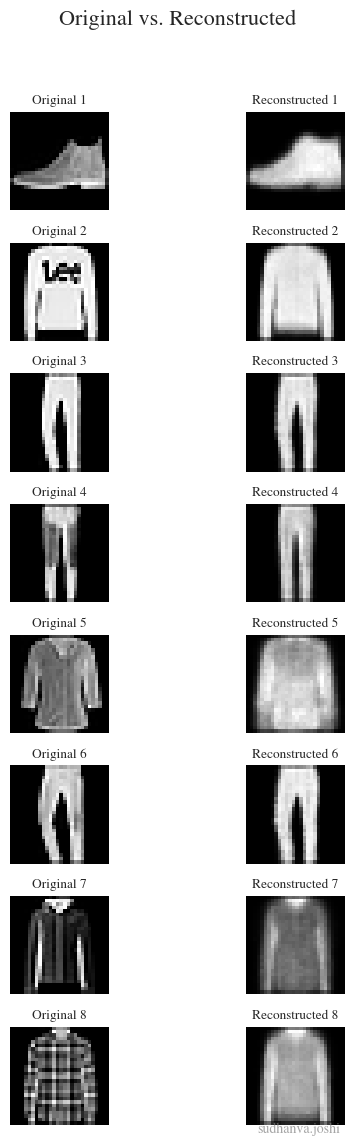

Generating new samples from N(0, I) prior.


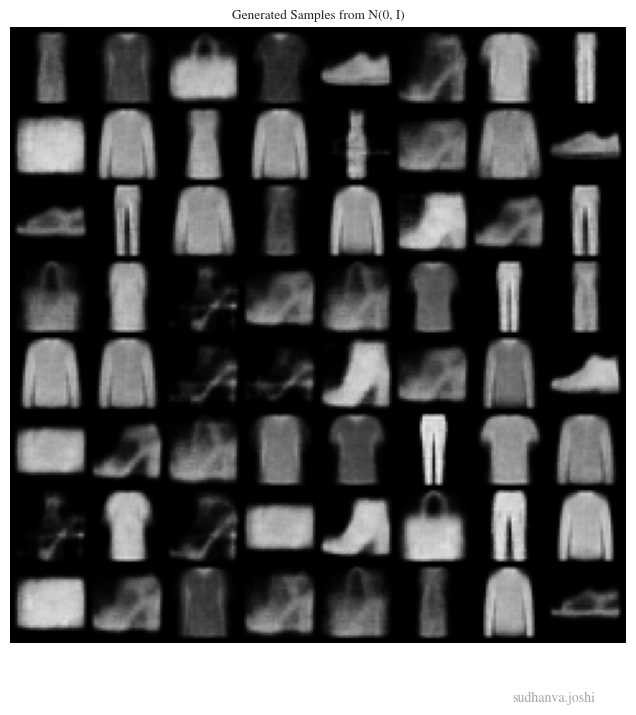

Preparing images for FID calculation.
Saved 10000 real images to fid_images/real
Saved 10000 generated images to fid_images/recon

Calculating FID score.


Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /home/sudhujoshi/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:20<00:00, 4.75MB/s]
100%|██████████| 200/200 [01:07<00:00,  2.96it/s]



FID Score (Lower is better)
Calculated FID: 135.6632


In [7]:
# We use the model from section 4.5 (model_beta1).
model_to_eval = model_beta1

# 1. Display Original vs. Reconstructed Images
print("Generating Original vs. Reconstructed images.")
model_to_eval.eval()

# Get a batch of test images
data, _ = next(iter(test_loader))
data = data.to(device)

with torch.no_grad():
    recon_x, _, _ = model_to_eval(data)

# Create a comparison grid
def show_comparison_grid(originals, reconstructions, num_images=8):
    originals = originals.cpu().view(-1, 28, 28)
    reconstructions = reconstructions.cpu().view(-1, 28, 28)
    
    fig, axes = plt.subplots(nrows=num_images, ncols=2, figsize=(6, num_images * 1.5))
    fig.suptitle("Original vs. Reconstructed", fontsize=16)
    
    for i in range(num_images):
        # Plot Original
        axes[i, 0].imshow(originals[i], cmap='gray')
        axes[i, 0].set_title(f"Original {i+1}")
        axes[i, 0].axis('off')
        
        # Plot Reconstructed
        axes[i, 1].imshow(reconstructions[i], cmap='gray')
        axes[i, 1].set_title(f"Reconstructed {i+1}")
        axes[i, 1].axis('off')
    
    add_username_to_plot(axes[num_images-1, 1])
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

show_comparison_grid(data, recon_x, num_images=8)

# 2. Generate New Samples from N(0, I) Prior
print("Generating new samples from N(0, I) prior.")
with torch.no_grad():
    # Sample z from the standard normal distribution
    z_samples = torch.randn(64, LATENT_DIM).to(device)
    
    # Decode the samples
    generated_images = model_to_eval.decode(z_samples).cpu()

# Plot the generated samples
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(make_grid(generated_images.view(-1, 1, 28, 28), nrow=8).permute(1, 2, 0))
ax.set_title("Generated Samples from N(0, I)")
ax.axis('off')
add_username_to_plot(ax)
plt.show()

# This section saves the real and generated images and then
# attempts to calculate the FID score directly in the notebook.

print("Preparing images for FID calculation.")
FID_NUM_SAMPLES = 10000 # The test set size

# Save Real Images
fid_real_dir = 'fid_images/real'
if not os.path.exists(fid_real_dir):
    os.makedirs(fid_real_dir)

# Save all test images
img_count = 0
for data, _ in test_loader:
    for i in range(data.size(0)):
        if img_count >= FID_NUM_SAMPLES:
            break
        save_image(data[i], os.path.join(fid_real_dir, f'real_{img_count}.png'))
        img_count += 1
    if img_count >= FID_NUM_SAMPLES:
        break
print(f"Saved {img_count} real images to {fid_real_dir}")

# Save Generated Images
fid_recon_dir = 'fid_images/recon'
if not os.path.exists(fid_recon_dir):
    os.makedirs(fid_recon_dir)

model_to_eval.eval()
with torch.no_grad():
    img_count = 0
    while img_count < FID_NUM_SAMPLES:
        # Generate in batches
        batch_size = min(BATCH_SIZE, FID_NUM_SAMPLES - img_count)
        z = torch.randn(batch_size, LATENT_DIM).to(device)
        fake_images = model_to_eval.decode(z)
        
        for i in range(fake_images.size(0)):
            save_image(fake_images[i].view(1, 28, 28), 
                       os.path.join(fid_recon_dir, f'recon_{img_count}.png'))
            img_count += 1
            
print(f"Saved {img_count} generated images to {fid_recon_dir}")

# Calculate FID directly in the notebook
print("\nCalculating FID score.")

try:
    from pytorch_fid import fid_score

    # Standard FID parameters
    dims = 2048
    batch_size = 50 
    
    fid_value = fid_score.calculate_fid_given_paths(
        paths=[fid_real_dir, fid_recon_dir],
        batch_size=batch_size,
        device=device,
        dims=dims
    )
    
    print(f"\nFID Score (Lower is better)")
    print(f"Calculated FID: {fid_value:.4f}")

except ImportError:
    print("\n ERROR: 'pytorch-fid' library not found.")
    print("To calculate FID, please install it by running this in a new cell:")
    print("\n!pip install pytorch-fid\n")
    print("After installation, re-run this cell.")

except Exception as e:
    print(f"\nAn error occurred during FID calculation: {e}")
    print("Please ensure 'pytorch-fid' is installed correctly.")
    print("Alternatively, run this command in a new cell or your terminal:")
    print(f"\n!python -m pytorch_fid {fid_real_dir} {fid_recon_dir}\n")

## 4.8 Effect of Frozen Latent Parameters

### Effect of $\sigma = 0.1$ (Low Variance)

**Diversity:**
The image diversity is extremely low. Because all latent samples $z$ are clustered very tightly around the origin
(the mean of the prior), the decoder produces images that all look very similar.

**Sharpness / Quality:**
The images represent the “average” of all classes in the dataset.
They look like a blurry, generic “clothing item” that is not clearly a shirt, shoe, or bag.


### Effect of $\sigma = 0.5$ (Medium Variance)

**Diversity:**
We see more diversity than $\sigma = 0.1$, but less than $\sigma = 1.0$.
The samples are distinct, but they don’t explore the “edges” of the latent space.
They are all “tamer” or more “average” versions of the items.

**Sharpness / Quality:**
The sharpness is similar to the $\sigma = 1.0$ case, as this is primarily a property of the decoder.


### Comparison to Standard Sampling ($\sigma = 1.0$)

The generation for $\sigma = 1.0$ is identical to the “standard stochastic sampling” from Section 4.7,
as we are sampling from the same $\mathcal{N}(0, I)$ prior that the model was trained on.
This serves as our **baseline**.


### Conclusion

The variance ($\sigma$) of the sampling distribution directly controls the **diversity** of the generated images.
A low $\sigma$ “collapses” the output toward the mean of the learned data distribution,
while a $\sigma$ matching the prior ($\sigma = 1.0$) allows for full exploration of the learned latent space,
producing a diverse range of items.


Generating samples with frozen latent parameters (mu=0).

Generating with sigma = 0.1


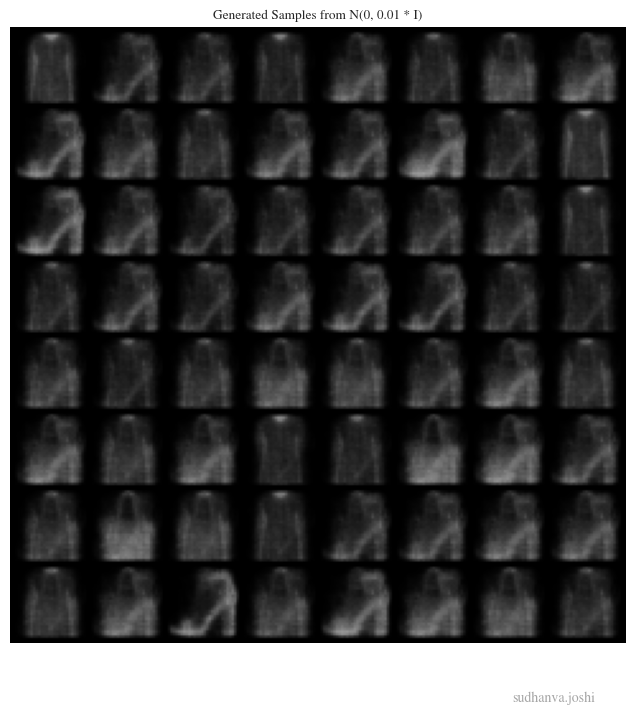


Generating with sigma = 0.5


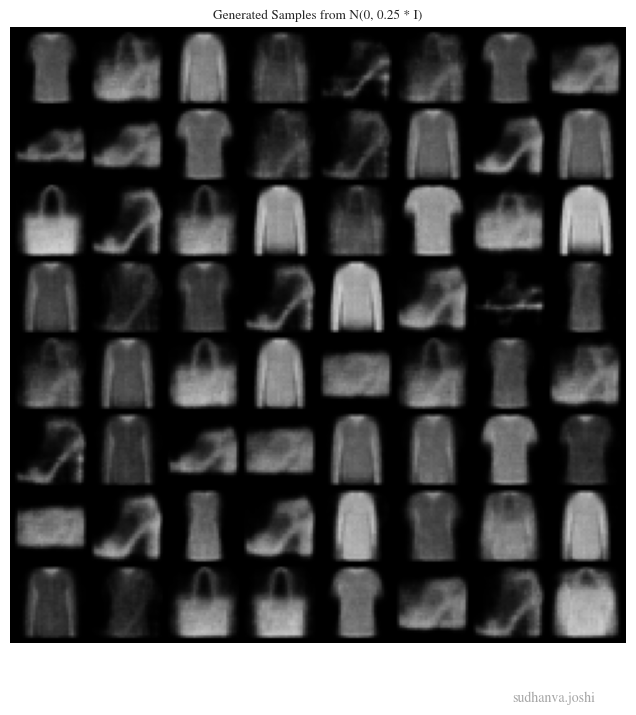


Generating with sigma = 1.0


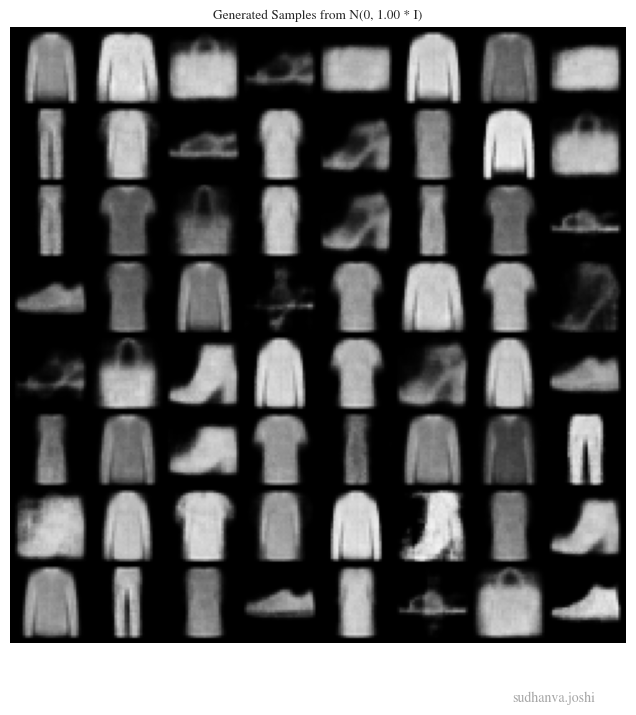

In [8]:
# We will use the decoder from our trained Beta=1 model
decoder = model_beta1.decode

print("Generating samples with frozen latent parameters (mu=0).")

# Loop over the specified sigma values
for sigma in [0.1, 0.5, 1.0]:
    print(f"\nGenerating with sigma = {sigma}")

    with torch.no_grad():
        # Sample z from N(0, sigma^2 * I)
        # z = mu + eps * sigma. Here mu=0.
        z_samples_frozen = torch.randn(64, LATENT_DIM).to(device) * sigma
        
        # Decode the samples
        generated_images = decoder(z_samples_frozen).cpu()

    # Plot the generated samples
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(make_grid(generated_images.view(-1, 1, 28, 28), nrow=8).permute(1, 2, 0))
    ax.set_title(f"Generated Samples from N(0, {sigma**2:.2f} * I)")
    ax.axis('off')
    add_username_to_plot(ax)
    plt.show()